# **EVAL AND EXPERIMENTS**

## **0. NEEDED IMPORTS**

In [1]:
# Basic Imports
import os
import sys
import json
import torch
import numpy as np 
import pandas as pd
import seaborn as sb
import pickle as pkl
from pathlib import Path
import matplotlib.pyplot as plt


In [2]:
# Run only one time
# 1. Get the base path
root = Path.cwd().parents[1]
# 2. Set that path as cwd
os.chdir(root)
# 3. Debug checking
print(f'·Aspect of the cwd:({Path.cwd()})')


·Aspect of the cwd:(/home/carlo/cuarto/GPT2_MOE/src)


In [3]:
# File system imports
device = 'cuda' if torch.cuda.is_available() else 'cpu'
from gpt2_moe.model import GPTMOE
from gpt2_moe.train_test.utils import Utils
from gpt2_moe.train_test.scorers import ScorerSelector
from gpt2_moe.train_test.configs import ExperimentConfig

CONFIG BASE DIR: /home/carlo/cuarto/GPT2_MOE/src/gpt2_moe/train_test/configs/cf_files


## **1. HISTORY AND MODEL LOADING**

In [4]:
def path_checker(path:str, create:bool = False)->None:
    """
        Function aimed to check path existance
        and in case it does not exist and 
        wanted, create it 

        Params:
            path (str):
                The path to check 

            create(bool):
                The creation flag

        Returns:    
            None:
                No value is returned
    
    """

    # Check existance
    existance = os.path.exists(path)  
    if not existance:
        # Info
        print(f'(path) Path ({path}) does not exist')
        # Check if creation is seeked
        if create:
            print(' ·Path created')
            os.makedirs(path)  
        return None
    print(f'(path) Path ({path}) exists')

In [5]:
# Define params
path_fake = 'images'
path_exist = 'gpt2_moe'

# Test the function 
# Does not exist
path_checker(path = path_fake)
# Does not exist -> creation
path_checker(path = path_fake, create = True)
# Created
path_checker(path = path_fake)

# Existed
path_checker(path = path_exist)


(path) Path (images) exists
(path) Path (images) exists
(path) Path (images) exists
(path) Path (gpt2_moe) exists


In [6]:
def weight_evo_retrieval(exp_name:str, path:str = 'gpt2_moe/checkpoints', seed:str = 'seed_42', model_name:str = 'full')->tuple[object, list[dict]]:
    """
        Function aimed to retrieve model weights 
        and its evo from a  given a source path

        Params:
            exp_name(str):
                The name of the experiment
            path(str):
                The source path
                Default value is gpt2_moe/checkpoints
            seed(str):
                The used to train the model
                Deafult value is 'seed_42'
            model_name(str):
                The name of the model to load
                Default name is 'full'
            

        Returns:
            A tuple of:
                - state_dict(collections.OrderedDict): Returns the state dict of the model 
                - history(list(dict)): Model's train evo 
            
    """

    # Check path existance
    if not os.path.exists(path):
        print(f'(w_loader) Debug :{' dir:'.join(list(os.scandir()))}')
        return {},{}

    # Define base full_path
    base_full_path = os.path.join(path, exp_name, seed, model_name)

    # Build the full path
    model_path = base_full_path + '.pth'
    print(f'(w_loader) Aspect of the full path ({model_path})')

    # Load the state_dict -> ensure no trojan is loaded :)
    state_dict = torch.load(model_path, weights_only = True)
    print(f'(w_loader) Weights loaded successfuly ({type(state_dict)})')

    # Load the evo 
    evo_path = base_full_path + '_history.json'
    with open(evo_path, mode = 'r') as file:
        evo = json.load(file)

    print(f'(w_loader) Evo loaded successfuly ({type(evo)})')

    return state_dict, evo

In [7]:
# Define mock params
path = 'gpt2_moe/checkpoints/'
exp_name = 'E2_scratch_moe_alternate'
seed = 'seed_42'

# Call the function
state_dict, evo = weight_evo_retrieval(path =  path, exp_name = exp_name, seed = seed)

(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


In [8]:
def model_loader(param_source_name:str, target_model:dict)->tuple[GPTMOE, list[dict]]:
    """
        Function aimed to load a model and its evo given
        a weight path and a param definition 
        path.


        Params:
            param_source_name(str):
                YAML name where params live
            target_model(dict):
                Dictioary containing needed data
                to retrieve the seeked model

        Returns:
            A tuple of:
                - model(GPTMOE): The initialized model 
                - evo (list(dict)): Model's training evo
    """

    # Get the params
    config = ExperimentConfig(name = param_source_name).get_model_params()
    
    # Initialize the model 
    model = GPTMOE(config)

    # Recover state_dict
    state_dict, evo = weight_evo_retrieval(**target_model)

    # Load the weights
    model.load_state_dict(state_dict)

    return model, evo

In [9]:
def experts_loader(param_source_name:str, base_name:str, target_model:dict, experts:int)->list[tuple[object, list[dict]]]:
    """
        Function acting as a wrapper for
        model_loader to enable experts 
        loading

        Params:
            param_source_name(str):
                YAML name where params live
            base_name(str):
                The expert base name
            target_model(dict):
                Dictionary containing needed data
                to retrieve the seeked model
            experts(int): 
                Amount of experts to load

        Returns:
            A list of tuples:
                - model(GPTMOE): The initialized model 
                - evo (list(dict)): Model's training evo
            
    """
    # Define the storage
    storage = []
    # Load each expert
    for i in range(experts):
        print(f'(expert_load)Loading expert {i}')
        # Define  expert name
        expert_name = base_name.format(i)
        print(f'    Selected expert:{expert_name}')
        # Update its name for loading
        target_model["model_name"]  = expert_name
        print(f'    Updated dict:{expert_name}')
        # Load weights and evo
        storage.append(model_loader(param_source_name = param_source_name, target_model = target_model))
        print()
    return storage


### **1.1.1 DENSE MODEL LOADING**

#### **FULL MODEL**

In [10]:
# Define the parameters
param_source_name = 'test_1.yaml'
target_model = {"exp_name": "E1_scratch_dense"}

# Load the model 
dense_model, evo_dense = model_loader(param_source_name = param_source_name, target_model = target_model)


(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E1_scratch_dense/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


### **1.1.2 ALTERNATE MODEL LOADING**

#### **LOAD THE INDIVIDUAL EXPERTS**

In [11]:
# Define the parameters
base_name = 'expert_{}'
param_source_name = 'test_2.yaml'
target_model = {"exp_name": "E2_scratch_moe_alternate"}

# Define the storage
n_experts = 6

# Load the experts 
experts_storage = experts_loader(param_source_name = param_source_name, base_name = base_name,  target_model = target_model, experts = 4)


(expert_load)Loading expert 0
    Selected expert:expert_0
    Updated dict:expert_0
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_0.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 1
    Selected expert:expert_1
    Updated dict:expert_1
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_1.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 2
    Selected expert:expert_2
    Updated dict:expert_2
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_2.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 3
    Selected expert:exper

#### **LOAD THE FULL MODEL**

In [12]:
# Define the parameters
param_source_name = 'test_2.yaml'
target_model = {"exp_name": "E2_scratch_moe_alternate"}

# Load the model 
full_alternate, full_alternate_evo = model_loader(param_source_name = param_source_name, target_model = target_model)


(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


## **2. TRAIN STUDY**

In [13]:
def nested_plot(ax:object, data:list[dict], label:str = None, task:list[str] = None)->None:
    """
        Function aimed to conduct a plot for nested data

        Params:
            ax(object):
                The ax to draw in 
            data(dict):
                The list of data dictionary per epoch
            label(str):
                The label for the plot
                Default value is None
            task(list(str)):
                The list of accepted tasks
                
        Returns:
            None:
                No value is returned
           
    """
    # Get base keys
    keys = data[0]
    # Check task
    if task is not None:
        if isinstance(task, str):
            task = [task]
        accepted = [key for key in keys if key in task]
    else:
        accepted = keys

    # Plot each task
    for key in accepted:
        # Plot each key data
        ax.plot([data_dict[key] for data_dict in data], label = f'{label} ({key})' if label else key)

In [ ]:
def versus_plotter(storages:list[list[dict]], params:list[str], aditional_config:dict = {}, filename:str = None)->None:
    """
    
        Funtion aimed to confront selected 
        data evolution for the given storages

        Params:
            storages (list(list(dict))):
                List containing evo storages
            params (list(str)):
                The params to plot
            aditional_config(dict):
                Aditional config for the plot

    """
    # Define base path
    base_path = 'images'

    # Count how many params we have
    n = len(params)
    #print(f'(plot) The amount of params: {n}')

    # Unpack aditional config
    st = len(storages)
    #print(f'(plot) The amount of storages: {st}')
    # As many names as storages
    names =  aditional_config.get('names', ['']*st)
    # As many titles as storages
    titles = aditional_config.get('titles', ['1']*n)
    # As many labels as plots
    ax_labels = aditional_config.get('labels', [["", ""] for _ in range(n)])
    # Free to do whatever you want
    plot_params = aditional_config.get('plot_params', {})

    # Define bypass for task specific
    task = aditional_config.get('selected_tasks', None)
    

    # Define flag  for task specific
    sp_flag = False
    
    # Create figure and subplots
    fig, axes = plt.subplots(1, n, figsize = (20,4), squeeze=False)


    # Plot data
    for ax, title, param, labels in zip(axes.flatten(), titles, params, ax_labels):
        # Exact_match
        sp_flag = param == 'exact_match'
        # Define plot title
        ax.set_title(title, fontweight = 'bold') 

        # Plot each storage data
        for storage, name in zip(storages, names):
            # Define storage
            data = []
            for epoch in storage:
                # Recover data
                data.append(epoch[param])
            # Plot data
            ax.plot(data, label = name, **plot_params) if not sp_flag else nested_plot(ax = ax, data = data, task = task,
                                                                                        label = name if st>1 else None)

        # Enhance the plot
        ax.set_xlabel(labels[0], color = 'red')
        ax.set_ylabel(labels[1], color = 'red')
        ax.legend(loc = 'best')
    # Tight the plot
    plt.tight_layout()

    # Store the figure
    if filename:
        # Check path
        path_checker(path = base_path)
        # Store image
        full_path = os.path.join(base_path, filename)
        plt.savefig(full_path, dpi = 600)

### **2.1 TRAIN LOSS STUDY**

**DENSE MODEL**

(path) Path (images) exists


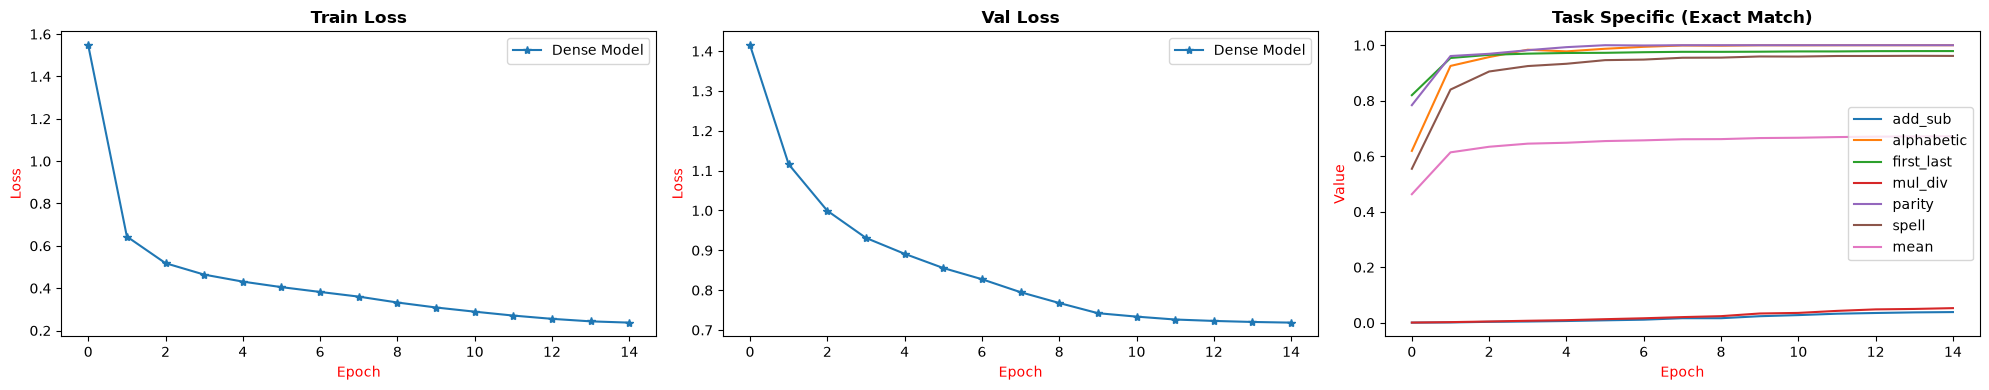

In [15]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [evo_dense]
aditional_config = {
                    "titles":["Train Loss", "Val Loss", "Task Specific (Exact Match)"],
                    "names":["Dense Model", "Dense Model", "Dense Model"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": None
                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'test1.png')

**ALTERNATE**

(path) Path (images) exists


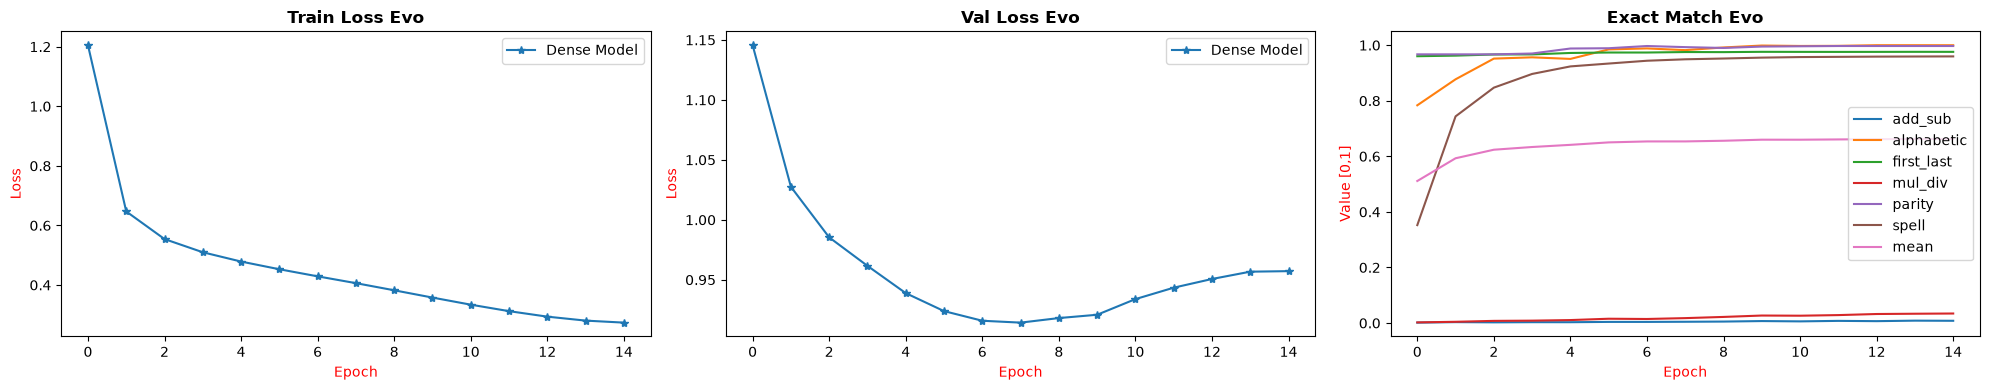

In [16]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [full_alternate_evo]
aditional_config = {
                    "titles":["Train Loss Evo", "Val Loss Evo", "Exact Match Evo"],
                    "names":["Dense Model", "Seq Alternate MoE"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value [0,1]"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": None
                    
                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'test2.png')

**COMPARISON**

(path) Path (images) exists


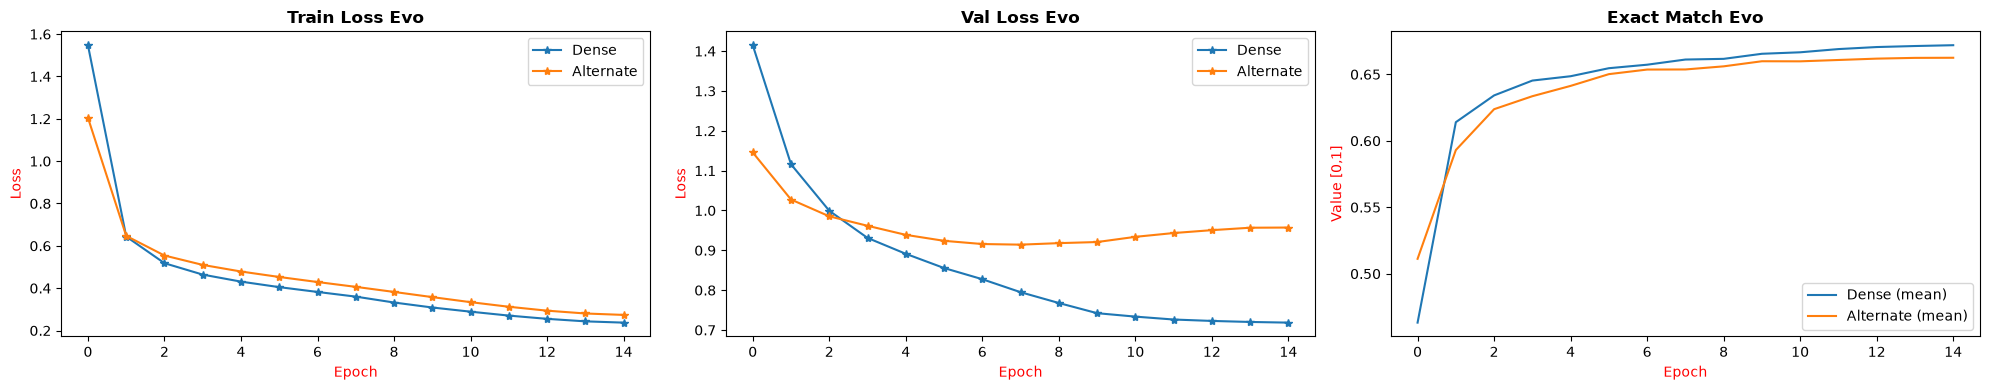

In [17]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [evo_dense, full_alternate_evo]
aditional_config = {
                    "titles":["Train Loss Evo", "Val Loss Evo", "Exact Match Evo"],
                    "names":["Dense", "Alternate"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value [0,1]"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": ['mean']
                    
                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'test3.png')

## **3. TEST QUALITY EVAL**

In [23]:
def benchmarking(models:list[GPTMOE], modelnames:list[str], context_length:int, device:str, metrics:list[str], tasks:list[str], seed:str)->None:
    """ 
        Function aimed to conduct benchmarking
        over a given model

        Params:
            model(list(GPTMOE)):
                The list of models
            modelnames(list(str)):
                The name of the models
            device(str):
                The selected device
            context_length(int):
                The length of the context
            metrics(str):
                The metric to use
            seed(str):
                The used seed
            
            tasks(list(str)):
                The list of tasks to evaluate 

        Returns:
            None:
                No value is returned
    """
    
    # Create the scorer
    scorer = ScorerSelector()

    # Iterate over models 
    for  model, modelname in zip(models, modelnames):
        # Info model
        print(f'MODEL({modelname})')
        # Move model to the device
        model.to(device = device)

        # Info seed
        print(f'(bm)Working with seed({seed})')
        # Get the loaders
        tl, vl, tel = Utils.get_loaders(tasks = tasks, batch_size = 64, context_length = context_length, seed = seed)
        print(f'    (dl)({seed}) Aspect of the test loader:', len(tel))
        # Evaluate on the metric
        results = scorer.run(metrics, model = model, loader = tel, device = device)
        print(f'    (results)({seed}) Aspect of results:', results)

        # Create df from results
        print(f'\n(bm)Aspect of the dataframe\n')
        results = pd.DataFrame(results)
        print(results, '\n')

        # Serialize data
        pickler(data = results, path = os.path.join('results', modelname))
        print('\n')

In [19]:
def pickler(data:object, path:str = 'results', base_name = 'results')->None:
    """ 
        Function aimed to pickle data

        Params:
            data(object):
                The data to pickle
            path(str):
                The path to store data at

        Returns:
            None:
                No value is returned
    """

    # Ensure path
    path_checker(path, create = True)
 
    # Get next name
    name = Utils.get_next_name(path, key =  base_name, ext = '.pkl')

    # Serialize data
    full_path = os.path.join(path, name)
    with open(full_path, mode = 'wb') as file:
        pkl.dump(data, file)

In [24]:
# Define params
seed = 42
model = {"dense":dense_model, "alternate": full_alternate}
tasks = ["add_sub", "mul_div", "alphabetic", "spell", "parity", "first_last"]
context_length = 64


# Call the benchmark per model
benchmarking(models = model.values(), modelnames = model.keys() , context_length = context_length, 
            metrics = ["exact_match", "token_ce"], tasks = tasks, seed = seed, device = device)



MODEL(dense)
(bm)Working with seed(42)
    (dl)(42) Aspect of the test loader: 89
(ce_t) Prediction aspect: torch.Size([64, 54, 50257])
(ce_t) Answer shape: torch.Size([64, 54])
(ce_t) Task shape: torch.Size([64])
(ce_t) Loss Shape torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
     (ce_t)(add_sub) Aspect of the task mask: torch.Size([64, 54])
     (ce_t)(alphabetic) Aspect of the task mask: torch.Size([64, 54])
     (ce_t)(first_last) Aspect of the task mask: torch.Size([64, 54])
     (ce_t)(mul_div) Aspect of the task mask: torch.Size([64, 54])
     (ce_t)(parity) Aspect of the task mask: torch.Size([64, 54])
     (ce_t)(spell) Aspect of the task mask: torch.Size([64, 54])
(ce_t) Prediction aspect: torch.Size([64, 54, 50257])
(ce_t) Answer shape: torch.Size([64, 54])
(ce_t) Task shape: torch.Size([64])
(ce_t) Loss Shape torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
     (ce_t)(add_sub) Aspect of the task mask: torch.Size([64, 54])
     (ce

## **4. HYPOTHESIS RELATED EXPERIMENTS**